# Week 3: Machine learning, saved model files and inventory scenarios

This notebook uses the supplied PDF’s Python data-science workflow. Run cells in order. Model fitting and evaluation are real computations; the bundled source is clearly labelled synthetic practice data.

## Learn, practise, complete
**Topics:** regression, Random Forest, pipelines, validation-based selection, held-out evaluation, saved weights, provenance, inventory scenarios.

**YouTube:** [StatQuest regression](https://www.youtube.com/@statquest/search?query=linear%20regression), [StatQuest Random Forest](https://www.youtube.com/@statquest/search?query=random%20forest).

**Websites:** [scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/), [evaluation metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).

**Your task:** explain the selected method, investigate large forecast errors, reproduce a saved-model prediction and hand-check an inventory scenario. Start a new experiment directory for a different dataset. Never claim synthetic metrics as real business evidence.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT/'src/data.py').is_file(), 'Open this notebook from the project or notebooks folder.'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
from src.data import read_sales, source_info, file_hash

# Change this to a licensed canonical sales CSV for your own analysis.
DATA_PATH = ROOT/'data/raw/demo_sales.csv'
data = read_sales(DATA_PATH)
source = source_info(DATA_PATH)
print('DATA SOURCE:', source['data_kind'])
print('SOURCE SHA-256:', source['source_sha256'])
print('Bundled data is synthetic practice data, not real retail observations.')
display(data.head())

DATA SOURCE: synthetic practice; not observed retail sales
SOURCE SHA-256: c0f8a91575ec1819cb02c4783d23f8e7d3d172d1cd83fce572aaff57302c67fc
Bundled data is synthetic practice data, not real retail observations.


,date,store,item,sales
0,2022-01-01,1,1,32
1,2022-01-02,1,1,28
2,2022-01-03,1,1,18
3,2022-01-04,1,1,11
4,2022-01-05,1,1,16


## 1. Choose model and report directories
The models directory stores actual fitted pipelines and JSON model metadata. Reports contain measured predictions and evaluation. Use separate directories when experimenting with real data so you do not overwrite the bundled practice artifacts.

In [2]:
from src.modeling import train,load_bundle,forecast_saved
MODEL_DIR=ROOT/'models/demo'
REPORT_DIR=ROOT/'reports/evaluation/demo'
if DATA_PATH.name!='demo_sales.csv':
    MODEL_DIR=ROOT/'models/retail'
    REPORT_DIR=ROOT/'reports/evaluation/retail'
print('Models:',MODEL_DIR.relative_to(ROOT))
print('Reports:',REPORT_DIR.relative_to(ROOT))

Models: models/demo
Reports: reports/evaluation/demo


## 2. Run real model fitting and evaluation
Compare naive, seasonal naive, Linear Regression and Random Forest. Selection uses validation MAE only; test errors are calculated after the choice. Learned evaluation models fit only the initial training partition. Serving pipelines are refitted after evaluation on all observed history. XGBoost is optional in the PDF and is not needed for this CPU-friendly implementation.

In [3]:
manifest=train(data,REPORT_DIR,source,model_directory=MODEL_DIR)
comparison=pd.concat({phase:pd.DataFrame(manifest[phase+'_metrics']).T for phase in ['validation','test']},names=['phase','model'])
display(comparison)
print('Selected method:',manifest['selected_model'])
assert manifest['selected_model']==min(manifest['validation_metrics'],key=lambda name:manifest['validation_metrics'][name]['mae'])

mae       rmse      bias  wape_percent  \
phase      model                                                             
validation naive               9.428571  11.467345  3.044643     24.985212   
           seasonal_naive      6.589286   8.227784  0.062500     17.461256   
           linear_regression   5.286253   6.647311  0.058084     14.008290   
           random_forest       5.232237   6.561159 -0.117577     13.865149   
test       naive              10.312500  12.795088  3.973214     26.381910   
           seasonal_naive      6.455357   8.053393 -0.446429     16.514390   
           linear_regression   5.215728   6.554924 -0.654108     13.343114   
           random_forest       5.342322   6.717385 -0.868809     13.666974   

                                  n  
phase      model                     
validation naive              224.0  
           seasonal_naive     224.0  
           linear_regression  224.0  
           random_forest      224.0  
test       naive              224.0  
           seasonal_naive     224.0  
           linear_regression  224.0  
           random_forest      224.0

Selected method: random_forest


## 3. Locate the trained models and their provenance

In [4]:
import json
registry=json.loads((MODEL_DIR/'registry.json').read_text())
display(pd.DataFrame([{'model':entry['name'],'file':entry['file'],'selected':entry['selected'],'sha256':entry['sha256']} for entry in registry['models']]))
display(pd.DataFrame([{'file':path.name,'bytes':path.stat().st_size} for path in sorted(MODEL_DIR.iterdir()) if path.is_file()]))
print('Selected binary:',(MODEL_DIR/'selected_model.joblib').relative_to(ROOT))
print('Baseline JSONs describe methods; .joblib files contain fitted scikit-learn pipelines.')

,model,file,selected,sha256
0,naive,naive.json,False,566997417c3889fd2f3d4473396a95257bebf05a1065a6...
1,seasonal_naive,seasonal_naive.json,False,89b7a0aa30a22fb4b907ce516533455dab5b3f97a5938f...
2,linear_regression,linear_regression.joblib,False,8b2ca7b803cf6bf1e9028cab214278cc1116d8094c5f63...
3,random_forest,random_forest.joblib,True,7f16e718a9243aabb4da8f536d0131e6f94e6552663a09...


,file,bytes
0,linear_regression.joblib,2402
1,manifest.json,6301
2,model_card.json,1218
3,naive.json,2311
4,random_forest.joblib,1071210
5,registry.json,4082
6,seasonal_naive.json,2350
7,selected_model.joblib,1071210


Selected binary: models/demo/selected_model.joblib
Baseline JSONs describe methods; .joblib files contain fitted scikit-learn pipelines.


## 4. Reload the selected model and reproduce its saved future forecasts

In [5]:
bundle=load_bundle(MODEL_DIR/'selected_model.joblib')
future=forecast_saved(data,bundle)
stored=pd.read_csv(REPORT_DIR/'forecast.csv',dtype={'store':str,'item':str},parse_dates=['date'])
np.testing.assert_allclose(future.prediction,stored.prediction,rtol=1e-10,atol=1e-10)
display(future.head(14))
processed=ROOT/'data/processed'; processed.mkdir(parents=True,exist_ok=True)
future.to_csv(processed/'forecasts_future.csv',index=False)

,date,store,item,prediction,model
0,2024-01-01,1,1,23.058641,random_forest
1,2024-01-01,1,2,27.851361,random_forest
2,2024-01-01,1,3,29.985103,random_forest
3,2024-01-01,1,4,38.954726,random_forest
4,2024-01-01,2,1,22.582587,random_forest
5,2024-01-01,2,2,30.420921,random_forest
6,2024-01-01,2,3,32.412909,random_forest
7,2024-01-01,2,4,45.111308,random_forest
8,2024-01-02,1,1,23.136915,random_forest
9,2024-01-02,1,2,28.594136,random_forest


## 5. Recompute held-out errors from saved predictions

In [6]:
from src.forecasting import metrics
test=pd.read_csv(REPORT_DIR/'test_predictions.csv',dtype={'store':str,'item':str},parse_dates=['date'])
selected=test[test.model==manifest['selected_model']]
recomputed=metrics(selected.actual,selected.prediction)
assert np.isclose(recomputed['mae'],manifest['test_metrics'][manifest['selected_model']]['mae'])
display(pd.Series(recomputed).to_frame('selected-model test metric'))
errors=test.assign(absolute_error=(test.prediction-test.actual).abs()).groupby(['model','store','item']).absolute_error.mean()
display(errors.to_frame('MAE by product'))

,selected-model test metric
mae,5.342322
rmse,6.717385
bias,-0.868809
wape_percent,13.666974
n,224.000000


MAE by product
model             store item                
linear_regression 1     1           4.617844
                        2           3.789644
                        3           4.752200
                        4           5.229521
                  2     1           3.849046
                        2           6.374796
                        3           6.242948
                        4           6.869827
naive             1     1           6.035714
                        2          10.642857
                        3           8.821429
                        4          14.035714
                  2     1           7.321429
                        2          11.035714
                        3          14.000000
                        4          10.607143
random_forest     1     1           4.761427
                        2           4.236942
                        3           5.153766
                        4           4.709999
                  2     1           4.185095
                        2           6.149710
                        3           6.152770
                        4           7.388871
seasonal_naive    1     1           5.821429
                        2           6.107143
                        3           6.464286
                        4           6.607143
                  2     1           4.500000
                        2           7.321429
                        3           7.392857
                        4           7.428571

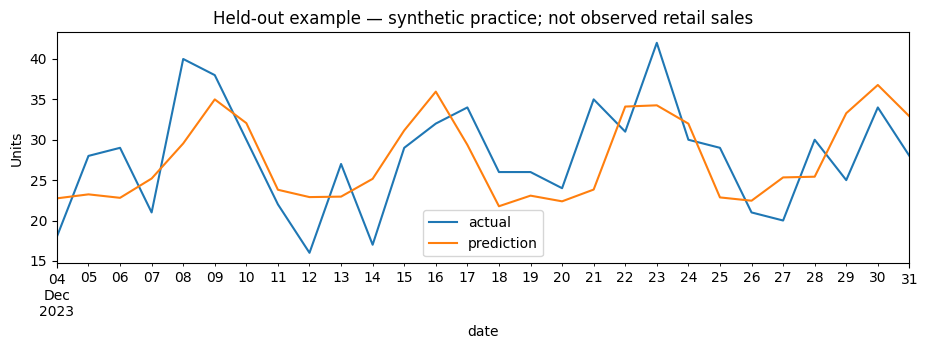

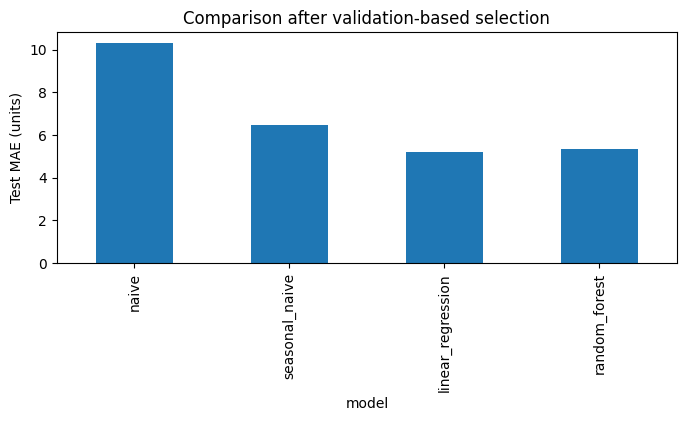

In [7]:
key=next(iter(data.groupby(['store','item']).groups))
example=selected[(selected.store==key[0]) & (selected.item==key[1])]
example.plot(x='date',y=['actual','prediction'],figsize=(11,3),title='Held-out example — '+source['data_kind'],ylabel='Units')
plt.show()
comparison.loc['test','mae'].plot.bar(figsize=(8,3),ylabel='Test MAE (units)',title='Comparison after validation-based selection')
plt.show()

## 6. Calculate an explicitly assumed inventory scenario
The dataset has no measured inventory or supplier lead time. The following numbers are hypothetical inputs. Safety stock uses a normal approximation, fixed lead time and independent daily-demand assumption. A service-level target is not a verified guarantee.

In [8]:
from src.inventory import inventory_scenario
path=future[(future.store==key[0]) & (future.item==key[1])].sort_values('date')
scenario=inventory_scenario(path.prediction,lead_days=3,review_days=1,on_hand=20,daily_std=5,
                            on_order=0,backorders=0,service_level=.95,pack_size=1)
display(pd.Series(scenario).to_frame('scenario result'))
(REPORT_DIR/'inventory_scenario.json').write_text(json.dumps(scenario,indent=2))
assert scenario['scenario_only'] is True

,scenario result
scenario_only,True
inventory_position,20.0
lead_time_demand,71.763068
safety_stock,14.24485
reorder_point,86.007918
target_stock,117.342627
reorder_now,True
suggested_order_units,98
inputs,"{'lead_days': 3, 'review_days': 1, 'on_hand': ..."
assumptions,Operator-supplied what-if inputs. Safety stock...


## Your Week 3 submission
Include actual metrics, model descriptions, training-data hashes, saved forecasts and error analysis. Explain why the selected method can differ from the lowest test-error method. Keep research claims separate from software checks; document your own changes and findings.